# $$Plan-Poiseuille Flow$$ 
### </br>$$\frac{1}{\mu} \frac{dP}{dx}= \frac{\partial ^2 U}{\partial y ^2}$$

No Slip condition at walls </br>
Pressure inlet is 10 units and outlet pressure is 5 units</br>
$\mu=0.1$

## Importing Libraries

In [58]:
# Import torch libraries
import torch
import torch.autograd as autograd  # helps in to find gradient
from torch import Tensor  # helps to convert the matrix to torch
import torch.nn as nn     # Neural network
import torch.optim as optim  # Optimization

# Libraries for ploting
from mpl_toolkits import mplot3d
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.pyplot import figure


import numpy as np  # Numpy
import time     # time
import math     # Math

# library for generating residual points
from pyDOE import lhs

# libraries for saving datafiles
from numpy import asarray
from numpy import savetxt

## Set seed values for Random number generation

In [59]:
# Random number
torch.set_default_dtype(torch.float)
torch.manual_seed(1234)
np.random.seed(1234)

## Check GPU

In [60]:
torch.cuda.empty_cache() # Empty the cache memory
device=torch.cuda.get_device_name() # Save the device name of gpu

print("- Original device name:", device)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("- Now device name is:- ", device)

- Original device name: NVIDIA GeForce RTX 3060 Laptop GPU
- Now device name is:-  cuda


## Generate Data Points

In [61]:
data_x=np.linspace(-1,1,100) # Generate data x (position) from -1 to 1
data_y=np.linspace(-1,1,100) # Generate data y (position) from -1 to 1

# Generate meshgrid for x and y coordinates
X,Y=np.meshgrid(data_x,data_y)


#savetxt('X',X,delimiter=',')
#savetxt('Y',Y,delimiter=',')

# Flatten the data [values,None]
X_flat=X.flatten()[:,None]
Y_flat=Y.flatten()[:,None]

# Flatten the grid structure to a matrix of size [100*100 X 2]
XY_Test=np.hstack((X.flatten()[:,None],Y.flatten()[:,None]))
print("Shape of XY_Test:",XY_Test.shape)


#XY_Test1=np.reshape(XY_Test,(100,100),order="F")

Shape of XY_Test: (10000, 2)


## Boundary Condition

Shape of all_xy_train: (400, 2) Shape of all_u_dp_train: (400, 1)


Text(0.5, 1.0, 'Plot to Show the Boundary')

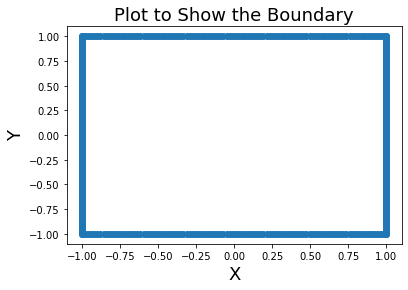

In [62]:
# Boundary at lower wall
xy_bc1=np.hstack((X[0,:][:,None],Y[0,:][:,None]))
u_bc1=np.zeros((xy_bc1.shape[0]))[:,None]

# Boundary at upper wall
xy_bc2=np.hstack((X[-1,:][:,None],Y[-1,:][:,None]))
u_bc2=np.zeros((xy_bc2.shape[0]))[:,None]

# Other wall
xy_bc3=np.hstack((X[:,0][:,None],Y[:,0][:,None]))
xy_bc4=np.hstack((X[:,-1][:,None],Y[:,-1][:,None]))

# Pressure at other wall
p_bc3=[10]*xy_bc3.shape[0]  # P=10 unit
p_bc3=np.array(p_bc3)[:,None]
#print(xy_bc4)
p_bc4=[5]*xy_bc4.shape[0]   # P=5 unit
p_bc4=np.array(p_bc4)[:,None]


#xy_bc5=np.hstack((X[50,:][:,None],Y[50,:][:,None]))
#u_bc5=np.array([50]*len(xy_bc5))[:,None]

# Stacking the values
all_xy_train=np.vstack((xy_bc1,xy_bc2,xy_bc3,xy_bc4))#,xy_bc5))
all_u_dp_train=np.vstack((u_bc1,u_bc2,p_bc3,p_bc4))#,u_bc5))

#N_u=100
#idx=np.random.choice(all_xy_train.shape[0],N_u,replace=False)
#all_xy_train=all_xy_train[idx,:]
#all_u_dp_train=all_u_dp_train[idx,:]


print("Shape of all_xy_train:",all_xy_train.shape,
      "Shape of all_u_dp_train:",all_u_dp_train.shape)


# Plot shows the boundary conditions (walls)
plt.scatter(all_xy_train[:,0],all_xy_train[:,1])
plt.xlabel("X",size=18)
plt.ylabel("Y",size=18)
plt.title("Plot to Show the Boundary",size=18)

## Generate Random data inside domain

Lower limit: [-1. -1.] Upper limit: [1. 1.]


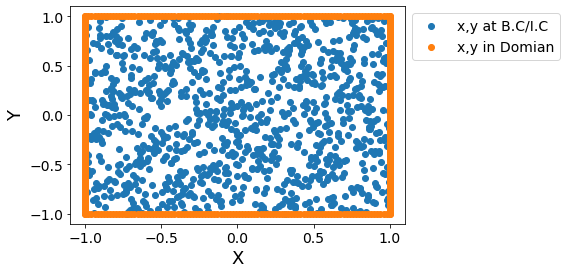

(1400, 2)


In [63]:
N_f=1000 # Number of residual points inside the domain


lb=XY_Test[0,:]    # Lower limit values
ub=XY_Test[-1,:]   # Upper limit values

# XY_f_train will have the 1000 values in the domain (Generated by lhs)
XY_f_train=lb+(ub-lb)*lhs(2,N_f)
print("Lower limit:",lb,"Upper limit:",ub)

# Scatter plot
plt.scatter(XY_f_train[:,0],XY_f_train[:,1],label="x,y at B.C/I.C")
plt.scatter(all_xy_train[:,0],all_xy_train[:,1],label="x,y in Domian")

plt.xlabel("X",fontsize=18)
plt.ylabel("Y",fontsize=18)
plt.tick_params(axis="x",labelsize=14)
plt.tick_params(axis="y",labelsize=14)

#plt.title("Random Data")
plt.legend(bbox_to_anchor =(1, 1),fontsize=14)
plt.show()

# XY_f_train values of residual and training points
XY_f_train=np.vstack((XY_f_train,all_xy_train))
print(XY_f_train.shape)

#savetxt('XY_f_train_xy',XY_f_train,delimiter=',')
#savetxt('XY_f_train_y',XY_f_train[:,1],delimiter=',')
#savetxt('all_xy_train_xy',all_xy_train,delimiter=',')
#savetxt('all_xy_train_y',all_xy_train[:,1],delimiter=',')


## Converting to Tensor

In [64]:
# .to(device) passing the values to the cuda (GPU)

udp_train=torch.from_numpy(all_u_dp_train).float().to(device)
xy_udp_train=torch.from_numpy(all_xy_train).float().to(device)
XY_f_train=torch.from_numpy(XY_f_train).float().to(device)

# f_hat is the matrix of size (XY_f_train.shape[0],1) for MSE_{LOSS}
f_hat=torch.zeros(XY_f_train.shape[0],1).to(device)
XY_Test=torch.from_numpy(XY_Test).float().to(device)


#print(udp_train.shape)
#print(xy_udp_train.shape)
#print(XY_f_train.shape)
#print(f_hat.shape)
#print(XY_Test.shape)

## PINNs

In [65]:
class PPF(nn.Module):
    
    def __init__(self,layers):
        
        super().__init__()
        
        # Define the activation function
        self.activation=nn.Tanh()
        
        # Define the loss function used (MSE)
        self.mse_loss=nn.MSELoss(reduction='mean')
        
        # Linear List for data storage
        self.linears=nn.ModuleList([nn.Linear(layers[i],layers[i+1]) for i in range(len(layers)-1)])
        
        # iter for counting purpose
        self.iter=0
        
        # setting initial valuesof weight and bias
        for i in range(len(layers)-1):
            nn.init.xavier_normal_(self.linears[i].weight.data,gain=5/3) # Weights as Xavier normal
            nn.init.zeros_(self.linears[i].bias.data)                 # Bias as Zero
    
    # Forward Pass
    def forward(self,x):
        
        # Check for torch if not then convert
        if torch.is_tensor(x)!=True:
            x=torch.from_numpy(x)
        
        # Convert lower and upper limit values to torch
        u_lim=torch.from_numpy(ub).float().to(device)
        l_lim=torch.from_numpy(lb).float().to(device)
        
        # Feature scaling
        x=(x-l_lim)/(u_lim-l_lim)
        a=x.float()
        
        # u pred and p pred should be same size of the input
        u_lin=torch.cat((a[:,[0]],a[:,[1]]),1)
        p_lin=torch.cat((a[:,[0]],a[:,[1]]),1)
        
        # Forward pass loss
        for i in range(len(layers)-2):
            z1=self.linears[i](u_lin) # Linear product (Wt.X) for velocity
            z2=self.linears[i](p_lin) # Linear product (Wt.X) for pressure
            
            u_lin=self.activation(z1)  # Passing by activation function
            p_lin=self.activation(z2)  # Passing by activation function
        
        # Consider the last layer with unit activation function
        u_lin=self.linears[-1](u_lin)
        p_lin=self.linears[-1](p_lin)
        
        # predict a=[u,p]
        a=torch.cat((u_lin,p_lin),1)
        
        # return the values of [u,p]=a
        return a
    
    # Loss function of boundary and initial condition
    def loss_BC(self,x,y):
        
        # BC1 and BC2
        xy_vel=x[0:200,:]
        
        # BC3,BC4
        xy_press=x[200:,:]
        
        # Velocity=[u,p]
        velocity=self.forward(xy_vel)
        
        # u--> predicted velocity for xy_vel
        u=velocity[:,[0]]
        
        
        #xy_vel2=x[400:500,:]
        #velocity_max=self.forward(xy_vel2)
        #umax=velocity_max[:,[0]]
        
        # pressure=[u,p]
        pressure=self.forward(xy_press)
        #pressure--> pressure valeus for xy_values
        pressure=pressure[:,[3]]

        # Calculate the MSE loss
        loss_velocity_bc=self.mse_loss(u,y[0:200,[0]])
        loss_pressure_bc=self.mse_loss(pressure,y[200:,[0]])
        #loss_velocity_max=self.mse_loss(umax,y[400:500,[0]])
        
        # sum of boundary loss
        total_bc_loss=loss_velocity_bc+loss_pressure_bc
        
        return total_bc_loss
    
    # Loss function for Domain + Boundary/Initial Points (PDE Loss)
    def loss_PDE(self,xy_to_train_f):
        muh=0.1  # As per equation
        
        # Create clone
        g=xy_to_train_f.clone()
        
        # Requires grad to be true
        g.requires_grad=True
        
        # Forward pass
        up=self.forward(g)
        
        # seperate the values
        u=up[:,[0]]
        p=up[:,[3]]

        # Calculating the gradient of U and P with respect to x and y
        u_xy=autograd.grad(u,g,torch.ones([xy_to_train_f.shape[0],1]).to(device),retain_graph=True,create_graph=True)[0]
        u_x=u_xy[:,[0]]
        u_y=u_xy[:,[1]]
        
        u_xxyy=autograd.grad(u_xy,g,torch.ones(xy_to_train_f.shape).to(device),create_graph=True)[0]
        u_xx=u_xxyy[:,[0]]
        u_yy=u_xxyy[:,[1]]
        
        p_xy=autograd.grad(p,g,torch.ones([xy_to_train_f.shape[0],1]).to(device),retain_graph=True,create_graph=True)[0]
        p_x=p_xy[:,[0]]
        p_y=p_xy[:,[1]]
        
        ###########
        # Partial differential equation
        fun=p_x-muh*(u_yy) # = 0
        ###########
        
        loss_f1=self.mse_loss(fun,f_hat)
        
        # Asssumptition #
        loss_f2=self.mse_loss(p_y,f_hat)
        loss_f3=self.mse_loss(u_x,f_hat)
        #               #
        
        #loss_assumption=abs(loss_f2)+abs(loss_f3)
        
        #file1=open('Assumptions_LOSS_Plan_poiseuille_Flow.txt','a')
        #file1.write(str(abs(loss_assumption).item())+'\n')
        #file1.close()
        
        # sum of PDE loss
        return loss_f1+loss_f2+loss_f3
    
    # Loss function which calls the Loss_bc and Loss_PDE and return the sum of both
    def loss(self,x,y,xy_to_train_f):
        
        loss1=self.loss_BC(x,y) # Call the function loss_bc
        loss2=self.loss_PDE(xy_to_train_f) # call the function loss_PDE
        
        # Total_loss of PDE and Boundary loss
        Total_loss= abs(loss1) + abs(loss2)
        
        # Saving the Data
        #file1=open('BC_LOSS_Plan_poiseuille_Flow.txt','a')
        #file1.write(str(abs(loss1).item())+'\n')
        #file1.close()
        
        #file1=open('PDE_LOSS_Plan_poiseuille_Flow.txt','a')
        #file1.write(str(abs(loss2).item())+'\n')
        #file1.close()
        
        #file3=open('TOTAL_LOSS_Plan_poiseuille_Flow.txt','a')
        #file3.write(str(Total_loss.item())+'\n')
        #file3.close()
        
        # Total Loss
        return Total_loss
    
    # Closure function 
    def closure(self):
        # Considereing the zero grad after every step
        optimizer.zero_grad()
        
        # call the loss funtion
        loss=self.loss(xy_udp_train,udp_train,XY_f_train)
        
        # Backward prop
        loss.backward()
        
        # counting iterations
        self.iter+=1
        
        # print after every 100 iterations
        if self.iter%100==0:
            print(loss)
        return loss
    
    # Test function returns the predicted the velocity and pressure
    def Test(self,xy_test):
        values=self.forward(xy_test)
        values=values.detach().cpu().numpy()
        u_pred=values[:,[0]]
        #u_pred=np.reshape(u_pred,(100,100),order="F")
        p_pred=values[:,[3]]
        #p_pred=np.reshape(p_pred,(100,100),order="F")
        
        #print("p_pred",u_pred.shape)
        #print("u_pred",u_pred.shape)
        return u_pred,p_pred

## Main Function

In [66]:
layers=[2,40,40,40,40,2] # Define the Number of neurons per layer

# Create Object passing Layers information to class PINNs
Plan=PPF(layers)
Plan.to(device)

params=list(Plan.parameters()) # Print Information of PINNs

# Optimization of LBFGS
optimizer=torch.optim.LBFGS(Plan.parameters(),lr=0.1,max_iter=10000,
                            tolerance_grad=1e-5,tolerance_change=1e-9,
                            history_size=1000,line_search_fn="strong_wolfe")

# Calculating the Time
start_time=time.time()
optimizer.step(Plan.closure) # Update the weights and bias terms
elapsed=time.time()-start_time

# Print the time for training
print("Training Time:",elapsed)

tensor(0.5207, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0119, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0015, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0005, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0002, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0001, device='cuda:0', grad_fn=<AddBackward0>)
tensor(7.6014e-05, device='cuda:0', grad_fn=<AddBackward0>)
tensor(4.4872e-05, device='cuda:0', grad_fn=<AddBackward0>)
tensor(3.0757e-05, device='cuda:0', grad_fn=<AddBackward0>)
tensor(2.3479e-05, device='cuda:0', grad_fn=<AddBackward0>)
tensor(1.9427e-05, device='cuda:0', grad_fn=<AddBackward0>)
tensor(1.4445e-05, device='cuda:0', grad_fn=<AddBackward0>)
Training Time: 81.50471329689026


## Predicting 

In [67]:
test_data1=(XY_Test[10::100])

test_data_xxx=(XY_Test[0:100,:])
#print(test_data_xxx)

test_data2=(XY_Test[30::100])
test_data3=(XY_Test[60::100])
test_data4=(XY_Test[90::100])

In [68]:
#[result_u,result_p]=Plan.Test(XY_Test)

In [69]:
#print(result_u.shape)
#print(result_p.shape)
#savetxt('result_u',result_u,delimiter=',')

In [70]:
#XY_Test=XY_Test.detach().cpu().numpy()
#XY_Test=np.reshape(XY_Test,(100,100),order="F")
#savetxt('XY_Test',XY_Test,delimiter=',')

In [71]:
[result_u1,result_p1]=(Plan.Test(test_data1))
result_u1=np.array(result_u1)

[result_u2,result_p2]=(Plan.Test(test_data2))
result_u2=np.array(result_u2)

[result_u3,result_p3]=(Plan.Test(test_data3))
result_u3=np.array(result_u3)

[result_u4,result_p4]=(Plan.Test(test_data4))

#Converting the list to array
result_p1=np.array(result_p1)
result_p2=np.array(result_p2)
result_p3=np.array(result_p3)
result_p4=np.array(result_p4)


[result_ux,result_px]=Plan.Test(test_data_xxx)
result_px=np.array(result_px)

---
---

In [72]:
XY_Test=XY_Test.detach().cpu().numpy() # Detach the values to the cpu

# x=0.21
test_data1=test_data1.detach().cpu().numpy()# Detach the values to the cpu

# x=0.39
test_data2=test_data2.detach().cpu().numpy()# Detach the values to the cpu

# x=0.79
test_data3=test_data3.detach().cpu().numpy()# Detach the values to the cpu
test_data_xxx=test_data_xxx.detach().cpu().numpy()# Detach the values to the cpu


## Plots

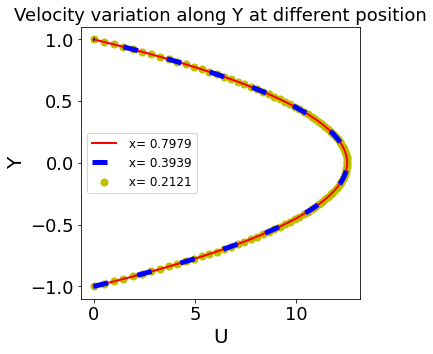

In [73]:
# Variation of velocity along Y direction

ax=plt.figure(figsize=(5,5))
plt.plot(result_u1,test_data1[:,1],color="r",label=' x= 0.7979',linewidth=2)
plt.plot(result_u2,test_data2[:,1],color="b",label=' x= 0.3939',linestyle='--',dashes=(3,6),linewidth=5)
plt.scatter(result_u3,test_data3[:,1],color="y",label=' x= 0.2121', s=50)
#plt.plot(result_u4,test_data4[:,1],color="m",label=' x= 0.8181')
plt.xlabel("U",fontsize=20)
plt.ylabel("Y",fontsize=20)
#plt.title("PINN Solution",fontsize=18)
plt.tick_params(axis="x",labelsize=18)
plt.tick_params(axis="y",labelsize=18)
plt.legend(fontsize=12)
plt.title("Velocity variation along Y at different position",size=18)
plt.show()

#savetxt('result_u1',result_u1,delimiter=',')
#savetxt('result_u2',result_u2,delimiter=',')
#savetxt('result_u3',result_u3,delimiter=',')
#savetxt('test_data1',test_data1[:,1],delimiter=',')

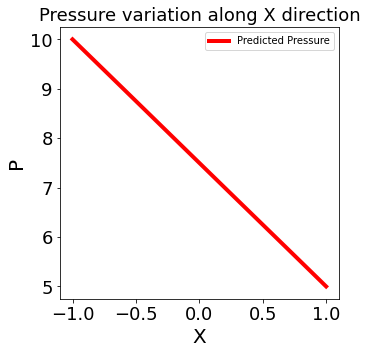

In [74]:
# Plot for variation of pressure along x direction

ax=plt.figure(figsize=(5,5))
#print(test_data1[:,0])

plt.plot(test_data_xxx[:,0],result_px,color="r",linewidth=4,label="Predicted Pressure")

#plt.title("Pressure Plot PINN Solution",fontsize=18)
plt.xlabel("X",fontsize=20)
plt.ylabel("P",fontsize=20)
plt.tick_params(axis="x",labelsize=18)
plt.tick_params(axis="y",labelsize=18)
plt.legend()
plt.title("Pressure variation along X direction",size=18)
plt.show()

#savetxt('test_data_xxx',test_data_xxx[:,0],delimiter=',')
#savetxt('result_px',result_px,delimiter=',')


---
---

## Exact Solution

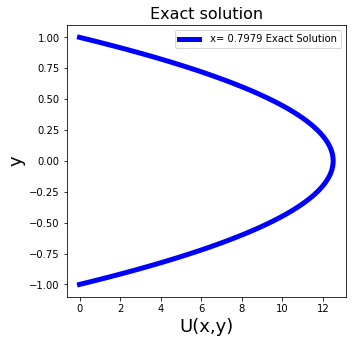

In [78]:
# Exact solution

ax=plt.figure(figsize=(5,5))

y_ll=np.linspace(-1,1,100)
u=(1/0.1)*(-5/4)*(y_ll**2)+(5/(4*0.1))
plt.plot(u,y_ll,color="b",label=' x= 0.7979 Exact Solution',linewidth=5)
plt.xlabel("U(x,y)",size=18)
plt.ylabel("y",size=18)
plt.legend()
plt.title("Exact solution",size=16)
plt.show()

---
---

## Comparison Plot

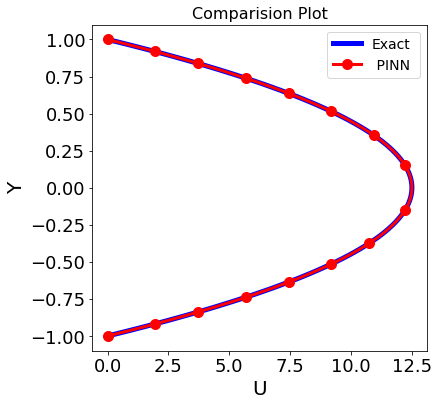

In [76]:
ax=plt.figure(figsize=(6,6))

plt.plot(u,y_ll,linewidth=5,color='blue',label='Exact')
plt.plot(result_u1,test_data1[:,1],color="r",label=' PINN ',linestyle='-',
         marker="o",markevery=0.1,markersize=10,linewidth=3)

#plt.title('Comparison between Analytical and PINN solution at x=0.7979',fontsize=20)
plt.xlabel("U",fontsize=20)
plt.ylabel("Y",fontsize=20)
plt.tick_params(axis="x",labelsize=18)
plt.tick_params(axis="y",labelsize=18)
plt.legend(fontsize=14)
plt.title("Comparision Plot",size=16)
plt.show()

#savetxt('u',u,delimiter=',')
#savetxt('result_u1',result_u1,delimiter=',')
#savetxt('test_data1',test_data1[:,1],delimiter=',')

---
---

## Relative L2 Error

$$\frac{||U_{Exact}-U_{Predicted}||_{L2}}{||U_{Exact}||_{L2}}$$

In [77]:
sum_pred=0
error=0
for i in range(len(u)):
    error+=((u[i]-result_u1[i])**2)
    sum_pred+=((u[i])**2)
    
error_root=error**0.5
sum_pred_root=sum_pred**0.5
print("The relative error is: ",error_root/sum_pred_root)

[6.960332e-05]


---
---